

# Introducción

El ejemplo básico de la utilidad de los métodos de Monte Carlo es el del cálculo de π por medio de aproximación. El objetivo de este ejemplo, es poder calcular el valor de π progresivamente, por medio de observaciones del ambiente.

En este caso, nuestro ambiente será un cuadrado de lado 2 en el plano cartesiano con un círculo de radio 1 y centro (0,0) definido dentro del cuadrado, como se muestra a continuación 

<img src="circulo_unitario.png" alt="circulo" width="150"/>
Figura 1. Círculo unitario en el plano cartesiano

Para el ambiente dado, los eventos de observación de nuestro algoritmo están definidos por la creación aleatoria de un punto en el plano. La recompensa de estos eventos está definida como 1, si el punto se encuentra dentro del círculo y 0 si el punto no se encuentra dentro del círculo, como se muestra a continuación.

$$
r(x,y) = \begin{cases}
1 & \text{ si } \sqrt{x^2 + y^2} \leq 1 \\
0 & \text{ de lo contrario }
\end{cases}
$$

Para realizar el cálculo, el agente debe llevar una cuenta de los puntos que se han ubicado dentro del círculo y los que no, tomando la proporción entre estos dos conjuntos de puntos como una estimación de π.


# Método de Monte Carlo

El primer paso para aplicar el método de Monte Carlo consiste en la generación del punto a ubicar en el ambiente por medio de la función generate_points(size). En el contexto de los MDPs, este paso es equivalente a la escogencia aleatoria de la acción del agente.



In [2]:
import random

def generate_points(size: float) -> tuple[float, float]:
    x = random.random()*size
    y = random.random()*size
    return (x, y)

      
Dado el punto generado, ahora es necesario observar si el punto se encuentra o no en el círculo, utilizando la fórmula de recompensa descrita anteriormente.

In [3]:
import math

def is_in_circle(point: tuple[float, float], size: float) -> bool:
    return math.sqrt(point[0]**2 + point[1]**2) <= size

def compute_pi(points_inside_circle: int, points_inside_square: int) -> float:
    return 4 * (points_inside_circle / points_inside_square)


Finalmente, teniendo una cantidad de puntos generados hasta el momento, es posible aproximar el valor de π utilizando la fórmula del área del círculo.
$$
\pi \approx 4 \cdot \frac{\text{puntos dentro del círculo}}{\text{total de puntos en el cuadrado}}
$$
La razón para multiplicar la proporción de los puntos por 4 es que la evaluación se realiza únicamente en el cuadrante positivo del círculo.  
#### Pruebas y resultados

Para demostrar el comportamiento del agente implementamos dos funciones de prueba, una para ver el cálculo progresivo del valor de π y otra que nos permita ver las observaciones del método de Monte Carlo.
Cálculo progresivo
Nuestra primera función de prueba calcula el valor de π dentro de cada iteración (i.e., episodio). Cada iteración del método de Monte Carlo consiste en tres pasos: (1) la generación de la observación (i.e., el punto), (2) el chequeo del resultado de la observación, y (3) el cálculo del valor  del objetivo de la función.  Este proceso se muestra a continuación.

In [4]:
def progressive_pi(sample_size:int):
    points_inside_circle = 0
    points_inside_square = 0
    for i in range(sample_size):
        point = generate_points(square_size) #square_size es una variable global a definir
        if is_in_circle(point, square_size):
            points_inside_circle +=1
        points_inside_square += 1
        print("The {} value of pi is {}".format(
            i + 1, compute_pi(points_inside_circle, points_inside_square)
        ))


La ejecución  de la función de prueba con distintos parámetros de iteración, deja ver como el método de Monte Carlo se acerca a el resultado correcto a medida que se van realizando más observaciones sobre el ambiente. 
Este hecho es precisamente la razón por la cual el método de Monte Carlo es utilizado para la solución de los problemas de MDP.

| 10 iteraciones | 50 iteraciones | 100 iteraciones |
| -------------- | -------------- | --------------- |
| The 5 value of pi is 1.6 |... | ... |
| The 6 value of pi is 2.0 | The 47 value of pi is 3.234042553191489 | The 97 value of pi is 3.0103092783505154 |
| The 7 value of pi is 1.7142857142857142 | The 48 value of pi is 3.25 | The 98 value of pi is 3.020408163265306 |
| The 8 value of pi is 2.0 | The 49 value of pi is 3.2653061224489797 | The 99 value of pi is 3.0303030303030303 |
| The 9 value of pi is 2.2222222222222223 | The 50 value of pi is 3.28 | The 100 value of pi is 3.04 |
| The 10 value of pi is 2.4 | | | 

## Aproximación de π 

La segunda función de prueba que utilizamos, muestra el cálculo completo de la aproximación de π, mostrando las observaciones generadas para 1000 observaciones

In [5]:
def full_pi(sample_size:int):
    points_inside_circle = 0
    points_inside_square = 0
    plt.axes().set_aspect('equal')
    plt.plot(1*np.cos(arc), 1*np.sin(arc))

    for _ in range(sample_size):
        point = generate_points(square_size)
        plt.plot(point[0], point[1], 'c.')
        points_inside_square += 1
        if is_in_circle(point, square_size):
            points_inside_circle += 1

    print("Approximate value of pi is {}" .format(compute_pi(points_inside_circle, points_inside_square)))



<img src="pi_319.png" alt="pi319" width="300"/>
Figura 2. Valor calculado de π=3.19       
<br>             
<img src="pi_306.png" alt="pi306" width="300"/>
Figura 3. Valor calculado de π=3.06


Intente ahora unificar toda la definición del cálculo de Monte Carlo (puede usar el código de referencia en [py-estimations.ipynb](https://github.com/FLAGlab/maia-aprendizaje-por-refuerzo/blob/main/semana5/py-estimations.ipynb)) y modifique la cantidad de iteraciones a ejecutar. ¿En qué punto la aproximación es precisa?


In [6]:
import numpy as np
import math
import random
import matplotlib.pyplot as plt
%matplotlib inline

square_size = 1
points_inside_circle = 0
points_inside_square = 0
#sample_size = 1000
arc = np.linspace(0, np.pi/2, 100)



n=      100: pi ≈ 3.120000; error absoluto = 0.021593
n=    1,000: pi ≈ 3.128000; error absoluto = 0.013593
n=   10,000: pi ≈ 3.126000; error absoluto = 0.015593
n=  100,000: pi ≈ 3.137280; error absoluto = 0.004313
n=1,000,000: pi ≈ 3.140592; error absoluto = 0.001001

Con este experimento, la primera aproximación con error < 0.01 aparece en n=100,000 iteraciones.


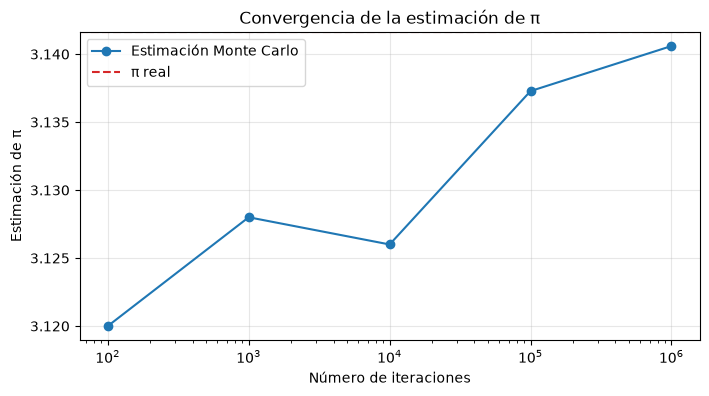

In [7]:
def monte_carlo_pi(sample_size: int, seed: int | None = None) -> float:
    """Estima pi con puntos uniformes en el primer cuadrante."""
    rng = random.Random(seed)
    points_inside_circle = 0

    for _ in range(sample_size):
        point = (rng.random() * square_size, rng.random() * square_size)
        points_inside_circle += is_in_circle(point, square_size)

    return compute_pi(points_inside_circle, sample_size)


# Se fija la semilla para que el experimento sea reproducible.
sample_sizes = [100, 1_000, 10_000, 100_000, 1_000_000]
estimates = [monte_carlo_pi(n, seed=42) for n in sample_sizes]
errors = [abs(estimate - math.pi) for estimate in estimates]

for n, estimate, error in zip(sample_sizes, estimates, errors):
    print(f"n={n:>9,}: pi ≈ {estimate:.6f}; error absoluto = {error:.6f}")

tolerance = 0.01
precise_sizes = [n for n, error in zip(sample_sizes, errors) if error < tolerance]
if precise_sizes:
    print(f"\nCon este experimento, la primera aproximación con error < {tolerance} "
          f"aparece en n={precise_sizes[0]:,} iteraciones.")
else:
    print(f"\nNingún tamaño probado alcanzó un error < {tolerance}.")

plt.figure(figsize=(8, 4))
plt.semilogx(sample_sizes, estimates, marker="o", label="Estimación Monte Carlo")
plt.axhline(math.pi, color="tab:red", linestyle="--", label="π real")
plt.xlabel("Número de iteraciones")
plt.ylabel("Estimación de π")
plt.title("Convergencia de la estimación de π")
plt.grid(alpha=0.3)
plt.legend()
plt.show()
